# 01 · Environmental predictors per H3 cell (local rasters)

This notebook averages global environmental rasters over every H3 resolution-3 cell in your trait file. It writes `env_data/env_predictors_h3r3.csv`, which notebook 02 reads.

**How it works:** every layer is first brought onto one common 2.5-arc-minute grid (~4.6 km at the equator). Each grid pixel is assigned to the H3 cell that contains its centre. Each cell then gets the area-weighted mean of its pixels; population is the exception (total persons ÷ land area). A res-3 cell contains about 600 such pixels, so the averages are stable.

**Effort:** downloads total a few GB. Processing takes roughly 10–20 minutes on one core and needs about 4 GB of RAM. The heaviest step is the 300 m land-cover map, which is read in strips.

## Data to download

| Block | Product | Where | Put it in |
|---|---|---|---|
| Climate | WorldClim 2.1, 2.5 min: `bio`, `tavg`, `tmin`, `tmax`, `prec`, `srad`, `wind`, `vapr` (19 + 7×12 = **103 variables**, as in Mahecha et al.) | `https://geodata.ucdavis.edu/climate/worldclim/2_1/base/wc2.1_2.5m_<var>.zip` (page: https://www.worldclim.org/data/worldclim21.html) | `env_raw/worldclim/` (unzipped `.tif`s) |
| Soil | SoilGrids 2.0, aggregated to 5 km: `bdod cec cfvo clay nitrogen ocd phh2o sand silt soc` + water retention `wv0010 wv0033 wv1500`, 6 depths, `mean` only (**78 layers**) | https://files.isric.org/soilgrids/latest/data_aggregated/5000m/ (one sub-folder per property) | `env_raw/soilgrids/<property>/` |
| Population | GHS-POP R2023A, epoch 2020, 30 arc-sec, WGS84 | https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_POP_GLOBE_R2023A/GHS_POP_E2020_GLOBE_R2023A_4326_30ss/V1-0/ | `env_raw/ghs_pop/` (unzipped `.tif`) |
| Land cover | ESA CCI Land Cover 2020, v2.1.1, 300 m (netCDF). Needs a free Copernicus CDS account. | https://cds.climate.copernicus.eu/datasets/satellite-land-cover (Download tab: variable *all*, year *2020*, version *v2.1.1*) | `env_raw/landcover/` (the `.nc` file) |

Two download scripts sit next to the notebooks. Run them on the cluster from a node with internet access. Both are safe to re-run, and they check what they downloaded: layer counts for WorldClim, SHA-256 checksums for SoilGrids.

```bash
bash download_worldclim.sh      # → env_raw/worldclim/   103 GeoTIFFs, ~1 GB
bash download_soilgrids.sh      # → env_raw/soilgrids/   78 GeoTIFFs, ~450 MB
```

Population and land cover only need downloading if you are not using your per-cell tables (see below).

Section 1 below checks what it finds and tells you what is missing.

**Land cover, two options:**

- **Per-cell table already aggregated to H3:** set `LANDCOVER_CSV` to the file (e.g. your colleague's `landcover_summary.csv` with `urban, crop, nat, barren, water`). Then no land-cover raster is needed and the ESA CCI step is skipped.
- **ESA CCI raster:** leave `LANDCOVER_CSV = None` and put the `.nc` file in `env_raw/landcover/`.

Without either, set `USE_LANDCOVER = False` in notebook 02.

**Population density** has three options:

- **A density raster:** `POP_DENSITY_TIF`, e.g. GPW v4 2020 in persons/km². Any resolution works; this is the default and uses your 1° GPW file.
- **A per-cell table:** `POP_CSV`.
- **The GHS-POP count raster** in `env_raw/ghs_pop/`, used if both of the above are `None`.

In [4]:
# %pip install numpy pandas rasterio h3 matplotlib   # once, if missing
import re
from pathlib import Path

import numpy as np
import pandas as pd
import h3
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import reproject
from rasterio.windows import Window
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## Settings

In [5]:
TRAIT_CSV = Path("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")
RAW_DIR = Path("~/Func_Neo_Phytes/Data/env_raw/").expanduser()
OUT_CSV = Path("~/Func_Neo_Phytes/Data/env_data/env_predictors_h3r3.csv").expanduser()

H3_RES    = 3
N_THREADS = 4                                     # threads for raster reprojection

# Land cover: a per-cell table already aggregated to H3 (columns: h3 id + class fractions).
# Set to None to compute fractions from the ESA CCI raster in env_raw/landcover/ instead.
LANDCOVER_CSV = Path("/net/scratch/swolf/GBIF/landcover_summary.csv")
LC_LAND_ONLY  = True   # rescale the land classes to shares of the land area (water stays a share of the whole cell)

# Population density, first match wins:
#   POP_DENSITY_TIF: a raster of persons/km² (e.g. GPW v4), area-weighted onto each H3 cell
#   POP_CSV:         a per-cell table (columns: h3 id + density)
#   otherwise:       GHS-POP count raster in env_raw/ghs_pop/
POP_DENSITY_TIF = Path("~/Func_Neo_Phytes/Data/gpw_v4_population_density_rev11_2020_1_deg.tif").expanduser()
POP_CSV         = None   # e.g. Path("~/Func_Neo_Phytes/Data/h3_population_density.csv").expanduser()

# Optional extra climate rasters, e.g. the Global Aridity Index & PET database v3 (Zomer et al. 2022,
# figshare 7504448). Set the paths to the annual GeoTIFFs; None = skip. The scale converts the stored
# integers to real units (the aridity index is stored × 10,000).
ARIDITY_TIF   = RAW_DIR / "aridity" / "ai_v3_yr.tif"
ARIDITY_SCALE = 0.0001
PET_TIF       = None    # e.g. RAW_DIR / "aridity" / "et0_v3_yr.tif"   (mm per year)
PET_SCALE     = 1.0

# ESA CCI LCCS classes → 8 groups, following the IPCC land categories in the CCI-LC user guide
LC_GROUPS = {
    "cropland": [10, 11, 12, 20, 30, 40],
    "forest":   [50, 60, 61, 62, 70, 71, 72, 80, 81, 82, 90, 100, 160, 170],
    "grass":    [110, 130],
    "shrub":    [120, 121, 122],
    "wetland":  [180],
    "urban":    [190],
    "sparse":   [140, 150, 151, 152, 153, 200, 201, 202, 220],   # lichen/moss, sparse veg., bare, snow/ice
    "water":    [210],
}

## 1 · Find the input files

In [6]:
# expand "~" in every path (pathlib does not do this on its own)
TRAIT_CSV, RAW_DIR, OUT_CSV = (Path(p).expanduser() for p in (TRAIT_CSV, RAW_DIR, OUT_CSV))
LANDCOVER_CSV, POP_DENSITY_TIF, POP_CSV, ARIDITY_TIF, PET_TIF = (
    None if p is None else Path(p).expanduser()
    for p in (LANDCOVER_CSV, POP_DENSITY_TIF, POP_CSV, ARIDITY_TIF, PET_TIF))
print(f"Looking for rasters in {RAW_DIR} ({'exists' if RAW_DIR.is_dir() else 'DOES NOT EXIST'})")

wc_files = sorted((RAW_DIR / "worldclim").rglob("wc2.1_2.5m_*.tif"))
sg_files = sorted((RAW_DIR / "soilgrids").rglob("*_mean_*.tif"))
pop_files = sorted((RAW_DIR / "ghs_pop").rglob("GHS_POP_*.tif"))
lc_files = sorted((RAW_DIR / "landcover").rglob("*.nc")) + sorted((RAW_DIR / "landcover").rglob("*.tif"))

def wc_name(p):
    """wc2.1_2.5m_bio_1.tif -> wc_bio01 ; wc2.1_2.5m_tavg_01.tif -> wc_tavg_01"""
    var, num = re.match(r"wc2\.1_2\.5m_([a-z]+)_(\d+)\.tif", p.name).groups()
    return f"wc_bio{int(num):02d}" if var == "bio" else f"wc_{var}_{int(num):02d}"

def sg_name(p):
    """clay_0-5cm_mean_5000.tif -> sg_clay_0-5cm_mean"""
    return "sg_" + re.sub(r"_\d+$", "", p.stem)

print(f"WorldClim : {len(wc_files):3d} layers (expected 103)")
print(f"SoilGrids : {len(sg_files):3d} layers (expected 78 with water retention, 60 without)")
if POP_DENSITY_TIF is not None:
    print(f"Population: density raster {POP_DENSITY_TIF} ({'found' if Path(POP_DENSITY_TIF).exists() else 'NOT FOUND'})")
    pop_files = []                                  # GHS-POP not needed
elif POP_CSV is not None:
    print(f"Population: per-cell table {POP_CSV} ({'found' if Path(POP_CSV).exists() else 'NOT FOUND'})")
    pop_files = []                                  # raster not needed
else:
    print(f"GHS-POP   : {len(pop_files):3d} file(s) (expected 1)")
if LANDCOVER_CSV is not None:
    print(f"Land cover: per-cell table {LANDCOVER_CSV} ({'found' if Path(LANDCOVER_CSV).exists() else 'NOT FOUND'})")
    lc_files = []                                   # raster not needed
else:
    print(f"Land cover: {len(lc_files):3d} raster file(s) (expected 1, optional)")
assert wc_files, "No WorldClim files found. Check RAW_DIR / the folder layout."
assert len(pop_files) <= 1 and len(lc_files) <= 1, "More than one population or land-cover file. Keep only one."

Looking for rasters in /net/home/swolf/Func_Neo_Phytes/Data/env_raw (exists)
WorldClim : 103 layers (expected 103)
SoilGrids :  78 layers (expected 78 with water retention, 60 without)
Population: density raster /net/home/swolf/Func_Neo_Phytes/Data/gpw_v4_population_density_rev11_2020_1_deg.tif (found)
Land cover: per-cell table /net/scratch/swolf/GBIF/landcover_summary.csv (found)


## 2 · Common grid and pixel → H3 assignment
The common grid is the WorldClim 2.5′ grid itself (8640 × 4320, −180…180, −90…90). Pixels with valid WorldClim data count as land. Each land pixel is assigned to the H3 cell containing its centre, and only cells in your trait file are kept.

In [7]:
RES = 1 / 24                     # 2.5 arc-minutes in degrees
W, H = 8640, 4320
DST_TRANSFORM = from_origin(-180, 90, RES, RES)
lat_c = 90 - (np.arange(H) + 0.5) * RES
lon_c = -180 + (np.arange(W) + 0.5) * RES

def to_grid(path, resampling=Resampling.average):
    """Read a raster onto the common grid as float32 with NaN for no-data."""
    with rasterio.open(path) as src:
        same = (src.crs is not None and src.crs.to_epsg() == 4326 and src.width == W and src.height == H
                and np.allclose(tuple(src.transform)[:6], tuple(DST_TRANSFORM)[:6], atol=1e-9))
        if same:
            return src.read(1, masked=True).astype("float32").filled(np.nan)
        dst = np.full((H, W), np.nan, dtype="float32")
        reproject(source=rasterio.band(src, 1), destination=dst,
                  src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                  dst_transform=DST_TRANSFORM, dst_crs="EPSG:4326", dst_nodata=np.nan,
                  resampling=resampling, num_threads=N_THREADS)
        return dst

land_ref = next((p for p in wc_files if wc_name(p) == "wc_bio01"), wc_files[0])
land = np.isfinite(to_grid(land_ref))
rows, cols = np.nonzero(land)
print(f"{land.sum():,} land pixels on the 2.5′ grid")

12,532,612 land pixels on the 2.5′ grid


In [8]:
# plain Python strings: h3 v3 rejects numpy string types
cell_ids = np.array(sorted(str(c) for c in pd.read_csv(TRAIT_CSV, usecols=["h3_res3"])["h3_res3"].unique()),
                    dtype=object)
n_cells = len(cell_ids)

# H3 ids as 64-bit integers (much lighter than strings); works with h3 v4 and v3
from h3.api import basic_int as h3i
to_cell_int = getattr(h3i, "latlng_to_cell", None) or h3i.geo_to_h3
str_to_int = getattr(h3, "str_to_int", None) or h3.string_to_h3
cell_ints = np.array([str_to_int(c) for c in cell_ids], dtype=np.uint64)
order = np.argsort(cell_ints)
sorted_ints = cell_ints[order]

code = np.full(len(rows), -1, dtype=np.int64)          # −1 = pixel not in one of your cells
CHUNK = 1_000_000
for s in range(0, len(rows), CHUNK):
    la, lo = lat_c[rows[s:s + CHUNK]], lon_c[cols[s:s + CHUNK]]
    ints = np.fromiter((to_cell_int(a, b, H3_RES) for a, b in zip(la.tolist(), lo.tolist())),
                       dtype=np.uint64, count=len(la))
    pos = np.clip(np.searchsorted(sorted_ints, ints), 0, len(sorted_ints) - 1)
    code[s:s + CHUNK] = np.where(sorted_ints[pos] == ints, order[pos], -1)
    if (s // CHUNK) % 5 == 0:
        print(f"  {s + len(la):,}/{len(rows):,} pixels assigned")
keep = code >= 0
rows, cols, code = rows[keep], cols[keep], code[keep]

# exact pixel area (km²) on the sphere, depends on latitude only
R = 6371.0088
lat_edges = np.radians(90 - np.arange(H + 1) * RES)
pix_area = (R ** 2) * np.radians(RES) * np.abs(np.sin(lat_edges[:-1]) - np.sin(lat_edges[1:]))
w = pix_area[rows]

n_pix = np.bincount(code, minlength=n_cells)
land_area = np.bincount(code, weights=w, minlength=n_cells)
print(f"{n_cells} trait cells; land pixels per cell: median {int(np.median(n_pix))}, "
      f"min {n_pix.min()}; {np.sum(n_pix == 0)} cells have no land pixel at 2.5′ (tiny islands → NaN)")

def hex_mean(grid):
    """Area-weighted mean of a common-grid layer per H3 cell (NaN pixels ignored)."""
    return hex_mean_values(grid[rows, cols])

def hex_mean_values(v):
    """Same, for values already given at the kept land pixels (aligned with rows/cols)."""
    ok = np.isfinite(v)
    num = np.bincount(code[ok], weights=(w * v)[ok], minlength=n_cells)
    den = np.bincount(code[ok], weights=w[ok], minlength=n_cells)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)

def hex_sum(grid):
    v = grid[rows, cols]
    ok = np.isfinite(v)
    return np.bincount(code[ok], weights=v[ok], minlength=n_cells)

ENV = {}

  1,000,000/12,532,612 pixels assigned
  6,000,000/12,532,612 pixels assigned
  11,000,000/12,532,612 pixels assigned
9752 trait cells; land pixels per cell: median 668, min 0; 11 cells have no land pixel at 2.5′ (tiny islands → NaN)


## 3 · Climate: WorldClim 2.1 (103 layers)

In [9]:
for i, p in enumerate(wc_files, 1):
    ENV[wc_name(p)] = hex_mean(to_grid(p))
    if i % 20 == 0 or i == len(wc_files):
        print(f"  {i}/{len(wc_files)} climate layers")

  20/103 climate layers
  40/103 climate layers
  60/103 climate layers
  80/103 climate layers
  100/103 climate layers
  103/103 climate layers


## 4 · Soil: SoilGrids 2.0, 5 km aggregates (78 layers)
The SoilGrids files use the Interrupted Goode Homolosine projection, the "orange peel" map cut into lobes. Some library versions misread the projection definition stored in the files. The data then lands in the wrong place, which shows up as large blocks of cells without soil, e.g. eastern North America and western Australia.

So this step uses the definition ISRIC documents for SoilGrids (`+proj=igh`) and checks it against the file's own definition. Whichever puts a soil value under more land pixels is used, and the result is printed.

There is no warping either. The centre of every land pixel on the 2.5′ grid is converted exactly into the SoilGrids projection with `pyproj`, and the 5 km soil value at that point is read. That is about one soil pixel per grid pixel, roughly 500 per H3 cell. All soil files share one grid, so the lookup is computed once.

The values keep SoilGrids' integer scaling (e.g. pH × 10). That doesn't matter here, because notebook 02 standardises every variable before the PCA.

In [10]:
from pyproj import Transformer

SOILGRIDS_CRS = "+proj=igh +lat_0=0 +lon_0=0 +datum=WGS84 +units=m +no_defs"   # as documented by ISRIC

_lookup = {}
def sample_at_pixels(path, crs=None):
    """Value of a raster at the centres of the kept land pixels; NaN outside / no-data.
    crs: projection to assume for the raster (default: the one stored in the file)."""
    with rasterio.open(path) as src:
        crs = crs or src.crs.to_wkt()
        key = (crs, tuple(src.transform), src.width, src.height)
        if key not in _lookup:
            tr = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
            x, y = tr.transform(lon_c[cols], lat_c[rows])
            c, r = ~src.transform * (x, y)
            c, r = np.floor(c), np.floor(r)
            inside = np.isfinite(c) & np.isfinite(r) & (c >= 0) & (r >= 0) & (c < src.width) & (r < src.height)
            _lookup[key] = (np.where(inside, r, 0).astype(np.int64), np.where(inside, c, 0).astype(np.int64), inside)
        r, c, inside = _lookup[key]
        a = src.read(1, masked=True).astype("float32").filled(np.nan)
    v = a[r, c]
    v[~inside] = np.nan
    return v

import pyproj
with rasterio.open(sg_files[0]) as src:
    file_crs = src.crs.to_wkt()
    print("SoilGrids file CRS read as:", src.crs.to_proj4())
print(f"(rasterio {rasterio.__version__}, GDAL {rasterio.__gdal_version__}, pyproj {pyproj.__version__}, PROJ {pyproj.proj_version_str})")
cov_file = np.isfinite(sample_at_pixels(sg_files[0], file_crs)).mean()
cov_igh  = np.isfinite(sample_at_pixels(sg_files[0], SOILGRIDS_CRS)).mean()
SG_CRS = SOILGRIDS_CRS if cov_igh >= cov_file else file_crs
print(f"land pixels with a soil value: {cov_file:.1%} with the file's own CRS, {cov_igh:.1%} with +proj=igh "
      f"→ using {'+proj=igh' if SG_CRS == SOILGRIDS_CRS else 'the file CRS'}")

for i, p in enumerate(sg_files, 1):
    ENV[sg_name(p)] = hex_mean_values(sample_at_pixels(p, SG_CRS))
    if i % 10 == 0 or i == len(sg_files):
        print(f"  {i}/{len(sg_files)} soil layers")

# coverage check: soil should exist for (almost) every cell that has climate data
first_sg = sg_name(sg_files[0])
n_miss = int(np.sum(np.isnan(ENV[first_sg]) & ~np.isnan(ENV[wc_name(land_ref)])))
print(f"{first_sg}: {n_miss} of {n_cells} cells have climate but no soil value "
      f"(a handful is normal: ice, glaciers, tiny islands)")

SoilGrids file CRS read as: +proj=goode +lon_0=0 +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs=True
(rasterio 1.2.10, GDAL 3.0.2, pyproj 2.6.1.post1, PROJ 6.2.1)
land pixels with a soil value: 62.4% with the file's own CRS, 92.5% with +proj=igh → using +proj=igh
  10/78 soil layers
  20/78 soil layers
  30/78 soil layers
  40/78 soil layers
  50/78 soil layers
  60/78 soil layers
  70/78 soil layers
  78/78 soil layers
sg_bdod_0-5cm_mean: 135 of 9752 cells have climate but no soil value (a handful is normal: ice, glaciers, tiny islands)


## 5 · Population density
**Option A, density raster (`POP_DENSITY_TIF`, e.g. GPW v4 in persons/km²):** the raster is resampled onto the 2.5′ grid with averaging, then each H3 cell gets the land-area-weighted mean density. That equals total persons ÷ land area.

This works even for a coarse 1° raster. A 1° pixel is about as large as a res-3 hexagon, so assigning pixel *centres* to hexagons leaves about 5% of your cells with no value and gives most others a single pixel. Here, every 2.5′ land pixel inherits the density of the 1° pixel it lies in, so each hexagon gets an area-weighted mix of all the 1° pixels it overlaps.

**Option B, per-cell table (`POP_CSV`):** the values are already per H3 cell, so they are only matched to your cells.

**Option C, GHS-POP raster:** population counts are summed onto the common grid, then summed per cell and divided by the cell's land area. The result is persons per km² of land.

In [11]:
def pop_from_table(path):
    t = pd.read_csv(path, sep=None, engine="python")
    t = t.loc[:, ~t.columns.str.startswith("Unnamed")]          # drop a saved pandas index column
    id_col = next(c for c in t.columns if "h3" in c.lower())
    val_col = next(c for c in t.columns if c != id_col and pd.api.types.is_numeric_dtype(t[c]))
    vals = t.groupby(id_col)[val_col].mean().reindex(cell_ids)
    print(f"{Path(path).name}: using column '{val_col}'; {vals.isna().sum()} of your {n_cells} cells not in the table; "
          f"median {vals.median():.1f}, max {vals.max():.0f}")
    return vals.to_numpy()

if POP_DENSITY_TIF is not None:
    dens_grid = to_grid(POP_DENSITY_TIF, Resampling.average)
    dens_grid[dens_grid < 0] = np.nan                # any negative no-data that slipped through
    ENV["pop_density"] = hex_mean(dens_grid)
    print(f"pop density: {np.isnan(ENV['pop_density']).sum()} of your {n_cells} cells without a value; "
          f"median {np.nanmedian(ENV['pop_density']):.1f} persons/km², max {np.nanmax(ENV['pop_density']):.0f}")
    del dens_grid
elif POP_CSV is not None:
    ENV["pop_density"] = pop_from_table(POP_CSV)
elif pop_files:
    pop_grid = to_grid(pop_files[0], Resampling.sum)
    pop_grid[pop_grid < 0] = np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        ENV["pop_density"] = np.where(land_area > 0, hex_sum(pop_grid) / land_area, np.nan)
    print(f"pop density: median {np.nanmedian(ENV['pop_density']):.1f} persons/km², "
          f"max {np.nanmax(ENV['pop_density']):.0f}")
    del pop_grid

ERROR 1: Invalid dfSouthLatitudeDeg
ERROR 1: Invalid dfSouthLatitudeDeg
ERROR 1: Invalid dfSouthLatitudeDeg
ERROR 1: Invalid dfSouthLatitudeDeg
ERROR 1: Invalid dfSouthLatitudeDeg
ERROR 1: Invalid dfSouthLatitudeDeg


pop density: 21 of your 9752 cells without a value; median 15.6 persons/km², max 9493


## 5b · Optional extra climate layers: aridity index and PET
The Global Aridity Index (precipitation ÷ potential evapotranspiration) is not one of the WorldClim layers, although it is computed from them. Zomer et al. derived PET from WorldClim 2.1 with the FAO-56 Penman–Monteith equation. So it adds no new information, but it does add an ecologically direct summary of water balance that the other variables only capture indirectly. Here it is averaged per cell like the other rasters, and stored as `cx_…` columns, which notebook 02 adds to the climate block.

Rough classes of the index: < 0.05 hyper-arid, < 0.2 arid, < 0.5 semi-arid, < 0.65 dry sub-humid, ≥ 0.65 humid.

In [12]:
for col, path, scale in [("cx_aridity_index", ARIDITY_TIF, ARIDITY_SCALE), ("cx_pet_mm", PET_TIF, PET_SCALE)]:
    if path is None:
        continue
    assert Path(path).exists(), f"{path} not found"
    grid = to_grid(path, Resampling.average)
    grid[grid < 0] = np.nan
    ENV[col] = hex_mean(grid) * scale
    del grid
    v = ENV[col]
    print(f"{col}: {np.isnan(v).sum()} cells without a value; 5th–50th–95th percentile "
          f"{np.nanpercentile(v, 5):.3g} / {np.nanmedian(v):.3g} / {np.nanpercentile(v, 95):.3g}")
    if col == "cx_aridity_index" and np.nanmedian(v) > 50:
        print("  ⚠ these look like stored integers. Check ARIDITY_SCALE (the index is usually 0–3).")

ERROR 1: Invalid dfNorthLatitudeDeg
ERROR 1: Invalid dfNorthLatitudeDeg
ERROR 1: Invalid dfNorthLatitudeDeg
ERROR 1: Invalid dfNorthLatitudeDeg
ERROR 1: Invalid dfNorthLatitudeDeg
ERROR 1: Invalid dfNorthLatitudeDeg


cx_aridity_index: 11 cells without a value; 5th–50th–95th percentile 0.0442 / 0.587 / 1.73


## 6 · Land cover
**Option A, per-cell table (`LANDCOVER_CSV`):** the fractions are already per H3 cell, so they are only matched to your cells. With `LC_LAND_ONLY = True`, urban, crop, natural and barren are rescaled to shares of the cell's *land*. That makes them comparable between coastal and inland cells, and consistent with the other predictors, which are averaged over land only. `water` stays as the share of the whole cell, where it acts as a coastal or island indicator. Cells that are at least 99% water get no land shares (NaN).

**Option B, ESA CCI raster:** the 300 m map is read in strips. Each 2.5′ pixel gets the share of its 300 m pixels in each group, and those shares are then averaged per H3 cell.

In [13]:
def landcover_fractions(path, chunk_rows=120):
    src_path = f'NETCDF:"{path}":lccs_class' if str(path).endswith(".nc") else str(path)
    lut = np.full(256, -1, dtype=np.int8)                      # LCCS code -> group index
    groups = list(LC_GROUPS)
    for g, codes in enumerate(LC_GROUPS.values()):
        lut[codes] = g
    out = {g: np.full((H, W), np.nan, dtype="float32") for g in groups}
    with rasterio.open(src_path) as src:
        t = src.transform
        f = int(round(RES / t.a))
        assert (abs(t.a * f - RES) < 1e-9 and abs(t.c + 180) < 1e-6 and abs(t.f - 90) < 1e-6
                and src.width == W * f and src.height == H * f), \
            f"Unexpected land-cover grid {src.width}×{src.height}, {t}. Expected a global lon/lat grid."
        for r0 in range(0, H, chunk_rows):
            nr = min(chunk_rows, H - r0)
            a = src.read(1, window=Window(0, r0 * f, W * f, nr * f))
            if a.dtype == np.int8:                             # unsigned byte stored as signed
                a = a.view(np.uint8)
            gi = lut[a.astype(np.uint8)]                       # 0 / no-data -> -1
            valid = (gi >= 0).reshape(nr, f, W, f).sum(axis=(1, 3))
            for k, g in enumerate(groups):
                cnt = (gi == k).reshape(nr, f, W, f).sum(axis=(1, 3))
                with np.errstate(invalid="ignore", divide="ignore"):
                    out[g][r0:r0 + nr] = np.where(valid > 0, cnt / valid, np.nan)
            if (r0 // chunk_rows) % 6 == 0:
                print(f"  rows {r0}/{H}")
    return out

def landcover_from_table(path):
    lc = pd.read_csv(path, sep=None, engine="python")          # comma- or tab-separated
    id_col = next(c for c in lc.columns if "h3" in c.lower())
    lc = lc.set_index(id_col).select_dtypes("number")
    print(f"{Path(path).name}: {len(lc)} cells; classes {list(lc.columns)}; "
          f"row sums median {lc.sum(axis=1).median():.3f} (min {lc.sum(axis=1).min():.3f}, max {lc.sum(axis=1).max():.3f})")
    out = lc.copy()
    if LC_LAND_ONLY and "water" in lc.columns:
        land_cols = [c for c in lc.columns if c != "water"]
        land_share = lc[land_cols].sum(axis=1)
        out[land_cols] = lc[land_cols].div(land_share.where(land_share >= 0.01), axis=0)
        print(f"  land classes rescaled to shares of land; {(land_share < 0.01).sum()} cells are ≥99% water → NaN")
    out = out.reindex(cell_ids)
    print(f"  {out.isna().all(axis=1).sum()} of your {n_cells} cells are not in the table")
    return out

if LANDCOVER_CSV is not None:
    for c, vals in landcover_from_table(LANDCOVER_CSV).items():
        ENV[f"lu_frac_{c}"] = vals.to_numpy()
elif lc_files:
    for g, grid in landcover_fractions(lc_files[0]).items():
        ENV[f"lu_frac_{g}"] = hex_mean(grid)
    print("land-cover fractions done")

landcover_summary.csv: 10194 cells; classes ['urban', 'crop', 'nat', 'barren', 'water']; row sums median 1.000 (min 1.000, max 1.000)
  land classes rescaled to shares of land; 392 cells are ≥99% water → NaN
  0 of your 9752 cells are not in the table


## 7 · Assemble, check, save

In [14]:
center = h3.cell_to_latlng if hasattr(h3, "cell_to_latlng") else h3.h3_to_geo
lat_lon = np.array([center(c) for c in cell_ids])
env = pd.DataFrame({"h3_index": cell_ids, "lat": lat_lon[:, 0], "lon": lat_lon[:, 1], "n_land_pixels": n_pix})
env = pd.concat([env, pd.DataFrame(ENV)], axis=1)

OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
env.to_csv(OUT_CSV, index=False)

blocks = {"climate": [c for c in env if c.startswith(("wc_", "cx_"))], "soil": [c for c in env if c.startswith("sg_")],
          "population": [c for c in env if c == "pop_density"], "land cover": [c for c in env if c.startswith("lu_frac_")]}
print(f"saved {OUT_CSV}: {env.shape[0]} cells × {env.shape[1]} columns")
for b, cols_b in blocks.items():
    if cols_b:
        print(f"  {b:<11} {len(cols_b):3d} vars, cells with any NaN: {env[cols_b].isna().any(axis=1).sum()}")
if blocks["land cover"]:
    lu_land = [c for c in blocks["land cover"] if not (LC_LAND_ONLY and LANDCOVER_CSV is not None and c == "lu_frac_water")]
    s = env[lu_land].sum(axis=1)
    print(f"  land-cover fractions sum to {s.median():.3f} (median), should be ≈ 1")

saved /net/home/swolf/Func_Neo_Phytes/Data/env_data/env_predictors_h3r3.csv: 9752 cells × 192 columns
  climate     104 vars, cells with any NaN: 11
  soil         78 vars, cells with any NaN: 171
  population    1 vars, cells with any NaN: 21
  land cover    5 vars, cells with any NaN: 256
  land-cover fractions sum to 1.000 (median), should be ≈ 1


Sanity maps: one variable from each block. Patterns should look familiar, e.g. warm tropics, dense population in South and East Asia, cropland in the Corn Belt and Punjab.

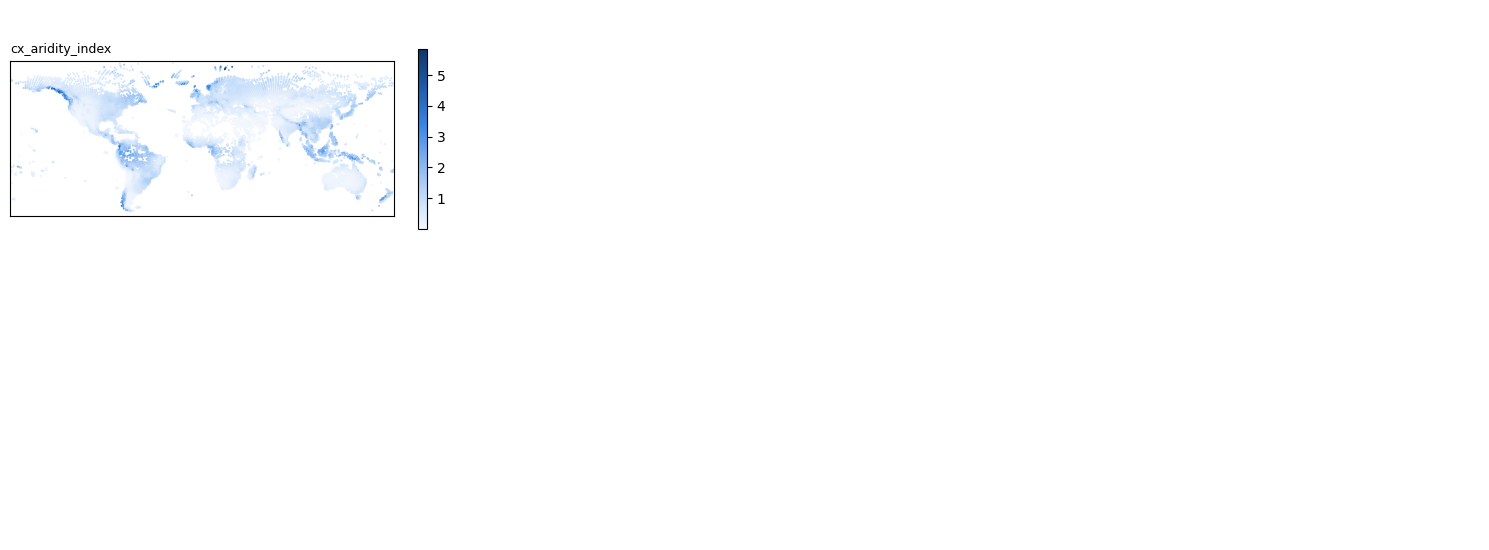

In [17]:
show = [c for c in ["cx_aridity_index"]
        if c in env]
fig, axes = plt.subplots(2, 3, figsize=(15, 5.6))
for ax, c in zip(axes.flat, show):
    v = np.log10(env[c] + 1) if c == "pop_density" else env[c]
    sc = ax.scatter(env["lon"], env["lat"], c=v, s=2, cmap=SEQ, linewidths=0, rasterized=True)
    ax.set_title(("log10 " if c == "pop_density" else "") + c, loc="left", fontsize=9)
    ax.set_xlim(-180, 180); ax.set_ylim(-60, 85); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, shrink=0.7)
for ax in list(axes.flat)[len(show):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

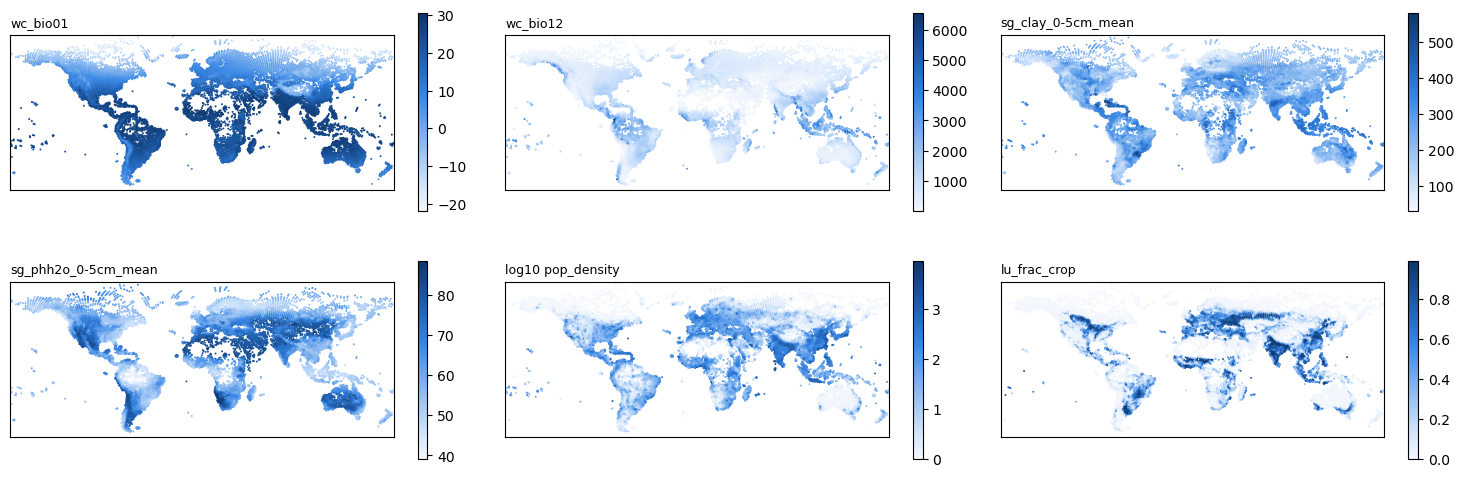

In [16]:
show = [c for c in ["wc_bio01", "wc_bio12", "sg_clay_0-5cm_mean", "sg_phh2o_0-5cm_mean", "pop_density", "lu_frac_cropland", "lu_frac_crop", "cx_aridity_index"]
        if c in env]
fig, axes = plt.subplots(2, 3, figsize=(15, 5.6))
for ax, c in zip(axes.flat, show):
    v = np.log10(env[c] + 1) if c == "pop_density" else env[c]
    sc = ax.scatter(env["lon"], env["lat"], c=v, s=2, cmap=SEQ, linewidths=0, rasterized=True)
    ax.set_title(("log10 " if c == "pop_density" else "") + c, loc="left", fontsize=9)
    ax.set_xlim(-180, 180); ax.set_ylim(-60, 85); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, shrink=0.7)
for ax in list(axes.flat)[len(show):]:
    ax.axis("off")
plt.tight_layout(); plt.show()